# Reference + pTx inversion centric TFL

PyPulseq port of `matlab/demoSeq/writeTFL_referenceInversion.m`.

The sequence contains two matched acquisitions in one Siemens measurement:

- **REP 0:** matched reference preparation + centric low-flip TFL.
- **REP 1:** pTx inversion preparation + identical centric low-flip TFL.

The external pTx pulse is loaded from an NPZ file. **The current notebook is
a sequence-construction framework. The final NPZ pulse path will be supplied
later.** No substitute pulse is provided. Confirm the corresponding mapVBVD
`Rep` dimension ordering in the first acquired Twix file, as in MATLAB.

## Imports and repository paths

Use a Python kernel with **this local PyPulseq fork** installed. From the outer
repository root, install it with `python -m pip install -e ./pypulseq`, then
restart the kernel. The local `pp.make_rf_shim` API writes the existing
MATLAB/interpreter `RF_SHIMS` extension.

Start the notebook from the repository root or a directory beneath it.

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pypulseq as pp

from pathlib import Path


In [2]:
repo_root = next(
    root for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "matlab/demoSeq/writeTFL_referenceInversion.m").is_file()
)
pulse_file = "/Users/jchen/Cambridge/Programming/GitLab/ptx-pulsedesign-optimization/matlab_reference/case11/pulses/3spoke_LUT_180.npz"  

**Set `pulse_file` before running the pulse-loading and sequence-build cells.**
For example, replace `None` with `Path("path/to/pulse_file.npz")`.
This is the only input-path edit needed. The output name is derived from the
selected pulse stem. No pulse search, MAT fallback, or simulated data is used.

## Experiment parameters

Lengths and times are in SI units. `n_rep = 1` describes one execution of each
arm; the Siemens/Pulseq REP labels distinguish reference (0) and inversion (1).
This source sequence supports one slice and one execution per arm.

In [3]:
fov = 224e-3
n_x = 64
n_y = 64
thickness = 3e-3
readout_flip_deg = 3
te = 2.5e-3
tr_inner = 6e-3
rf_spoiling_inc = 117  # degrees
n_slices = 1
n_rep = 1  # One execution per arm; REP 0/1 identifies reference/inversion.
prep_delay = 0
recovery_delay = 10  # s; experiment-specific recovery after the reference low-flip train.
assert n_rep == 1 and n_slices == 1

## System limits

These are the MATLAB sequence's limits: 28 mT/m and 150 T/m/s, with 10 µs
gradient and RF rasters. They are sequence-design inputs, independent of
a scanner's higher hardware maxima.

In [4]:
system = pp.Opts(
    max_grad=28, grad_unit="mT/m",
    max_slew=150, slew_unit="T/m/s",
    rf_ringdown_time=20e-6,
    rf_dead_time=100e-6,
    adc_dead_time=10e-6,
    grad_raster_time=10e-6,
    rf_raster_time=10e-6,
)

## External pTx pulse: NPZ contract

The future NPZ is the Python equivalent of the MATLAB pulse structure.
Store numeric arrays directly (no pickled objects).

| Field | Meaning and layout |
| --- | --- |
| `rf_detail` | `[n_sections, >=2]`; column 0 is the integer section sample count, column 1 is RF section type 0 (off) or 1 (active). Type 2 is unsupported. |
| `rf_form` | Scalar complex RF waveform samples, retaining source sample order. |
| `b_est` | Per-channel complex voltage waveform. **Retain the MATLAB sample/channel layout**, normally `[n_rf_samples, n_tx]`; do not transpose. The loader uses MATLAB/Fortran-order reshape. |
| `g_low` | Sampled `[Gx, Gy, Gz]`, shape `[n_grad_samples, 3]`, in mT/m. |
| `g_step` | Scalar gradient time step in **ms**, matching the MAT convention. |
| `oversample` | Scalar number of RF samples per gradient sample: `rf_dt = grad_dt / oversample`. |
| `alpha` | Optional nominal flip-angle metadata, in the source export's units; preserved without use in sequence construction. |

No flip-angle rescaling is inferred from `alpha`. Section counts describe
RF samples, not gradient samples. The source assumes successive active rows
occur in the standard **RF-off / RF-active / RF-off** spoke structure.

## n-spoke serialization

MATLAB `loadExternalSpokePulse` → Python `load_external_spoke_pulse`.

The source pulse may overlap in-plane positioning gradients with Gz ramps.
For scanner-compatible Pulseq blocks, serialize the waveform by axis:

- Z moment stays with each RF spoke.
- XY positioning moves into independent zero-to-zero PRE/blip/POST blocks.

This preserves **kx/ky at every RF centre** and the **total integrated
gradient moment**. It does not preserve the exact sampled gradient timing.

MATLAB uses 1-based half-open-style ranges assembled from cumulative edges.
Python uses ordinary zero-based half-open slices. These slices preserve the
same source samples and moments. Gradient-edge rounding uses `floor(x + 0.5)`
to reproduce MATLAB's rounding for nonnegative sample edges.

### Ordinary trapezoids with MATLAB's ramp timing

Local PyPulseq's default area/duration solver chooses different ramps from
MATLAB. This small helper ports MATLAB's continuous amplitude estimate and
raster-rounded rise time, then supplies that rise time to `pp.make_trapezoid`.
Use it for **all** area/duration trapezoids below so waveform parity is retained.

`make_moment_trap` tries the source/preferred duration first. A duration that
cannot realize the area under the system limits falls back to the shortest
legal ordinary trapezoid. This is MATLAB's `makeMomentTrap` rule.

In [5]:
def make_area_trapezoid(channel, area, duration, system):
    """MATLAB makeTrapezoid's area/duration ramp calculation."""
    dc = 1 / system.max_slew
    discriminant = duration**2 - 4 * abs(area) * dc
    if discriminant <= 0:
        raise ValueError("Duration is too short for area.")
    amplitude = (duration - np.sqrt(discriminant)) / (2 * dc)
    raster = system.grad_raster_time
    rise_time = max(raster, np.ceil(abs(amplitude) / system.max_slew / raster) * raster)
    return pp.make_trapezoid(
        channel, area=area, duration=duration, rise_time=rise_time, system=system
    )


def make_moment_trap(channel, area, preferred_duration, system):
    if preferred_duration > 0:
        try:
            return make_area_trapezoid(channel, area, preferred_duration, system)
        except ValueError:
            # These fixed channel/area inputs leave infeasible timing as the failure mode.
            pass
    return pp.make_trapezoid(channel, area=area, system=system)


def make_moment_block(area, preferred_duration, axes, system):
    """MATLAB makeMomentBlock: independent zero-to-zero gradients."""
    gradients = [
        make_moment_trap(channel, area[axis], preferred_duration, system)
        for axis, channel in enumerate("xyz")
        if axes[axis] and abs(area[axis]) > 1e-12
    ]
    duration = pp.calc_duration(*gradients) if gradients else preferred_duration
    return {"type": "moment", "grad": gradients, "duration": duration}


def source_row_moment(sections, rows):
    return sum((sections[row]["moments"] for row in rows), start=np.zeros(3))


def block_gradient_moment(block):
    moment = np.zeros(3)
    for grad in block["grad"]:
        moment["xyz".index(grad.channel)] += grad.area
    return moment

### Preserve each complete scalar RF package

MATLAB `makeSpokeBlock` → Python `make_spoke_block`.

For spoke $s$, take the largest-magnitude scalar sample in its active row:

$$w_s = B_{\rm volt}(t_{\rm peak},:) / rf_{\rm form}(t_{\rm peak}),\qquad
shim_s = w_s / 223,\qquad signal_{\rm Hz}(t)=500\,rf_{\rm form}(t).$$

The **500 Hz ↔ 223 V** calibration is unchanged. One constant RF_SHIMS vector
multiplied by the scalar RF waveform reconstructs the per-channel voltage
waveform for each rank-1 spoke. There is no factorization or shim normalization.

The RF includes both neighbouring RF-off sections, without added samples.
Replace its sampled Gz with one ordinary trapezoid of the same Z moment and
the **full RF-event duration** (including dead time and ringdown).

In [6]:
def make_spoke_block(signal_hz, rf_dt, area_z, system):
    integral = np.sum(signal_hz) * rf_dt
    integral_tolerance = np.spacing(max(1, np.linalg.norm(signal_hz, 1) * rf_dt))
    # MATLAB's zero-integral dummy branch retains the package midpoint as RF centre.
    center = signal_hz.size * rf_dt / 2 if abs(integral) <= integral_tolerance else None
    rf = pp.make_arbitrary_rf(
        signal_hz, flip_angle=2 * np.pi * abs(integral),
        dwell=rf_dt, no_signal_scaling=True, center=center,
        delay=system.rf_dead_time, system=system, use="excitation",
    )
    gz = make_area_trapezoid("z", area_z, pp.calc_duration(rf), system)
    return {
        "type": "spoke", "rf": rf, "grad": [gz],
        "duration": pp.calc_duration(rf, gz),
    }

In [7]:
def load_external_spoke_pulse(pulse_file, system):
    """Moment-preserving, axis-separated n-spoke serialization of the NPZ source."""
    with np.load(pulse_file, allow_pickle=False) as pulse:
        rf_detail = np.asarray(pulse["rf_detail"], dtype=float)
        rf_form = np.asarray(pulse["rf_form"], dtype=complex).ravel(order="F")
        grad_dt = float(np.asarray(pulse["g_step"]).item()) * 1e-3
        rf_dt = grad_dt / float(np.asarray(pulse["oversample"]).item())
        b_volt = np.asarray(pulse["b_est"], dtype=complex).reshape((rf_form.size, -1), order="F")
        gradients = np.asarray(pulse["g_low"], dtype=float) * 1e-3 * system.gamma  # Hz/m
        alpha = np.array(pulse["alpha"], copy=True) if "alpha" in pulse else None

    assert np.all(np.isin(rf_detail[:, 1], [0, 1]))
    edges = np.concatenate(([0], np.cumsum(rf_detail[:, 0]))).astype(int)
    grad_edges = np.floor(edges * rf_dt / grad_dt + 0.5).astype(int)
    rf_rows = np.where(rf_detail[:, 1] == 1)[0]
    n_spokes = len(rf_rows)
    n_rows = len(rf_detail)
    assert np.all(np.diff(rf_rows) == 3)
    rf_tolerance = 1e-12
    time_tolerance = 1e-12
    moment_tolerance = 1e-10 * np.maximum(1, np.sum(abs(gradients), axis=0) * grad_dt)

    sections = [
        {
            "rf_samples": slice(edges[row], edges[row + 1]),
            "moments": np.sum(gradients[grad_edges[row]:grad_edges[row + 1]], axis=0) * grad_dt,
        }
        for row in range(n_rows)
    ]
    packages = []
    for row in rf_rows:
        assert 0 < row < n_rows - 1
        assert rf_detail[row - 1, 1] == 0 and rf_detail[row + 1, 1] == 0
        samples = slice(edges[row - 1], edges[row + 2])
        grad_samples = slice(grad_edges[row - 1], grad_edges[row + 2])
        active = sections[row]["rf_samples"]
        peak_sample = edges[row] + np.argmax(abs(rf_form[active]))
        weights_v = b_volt[peak_sample] / rf_form[peak_sample]
        reconstructed = rf_form[samples, None] * weights_v[None, :]
        relative_error = np.linalg.norm(reconstructed - b_volt[samples]) / max(
            np.linalg.norm(b_volt[samples]), np.finfo(float).eps
        )
        assert relative_error < rf_tolerance
        packages.append({
            "rf_samples": samples, "weights_v": weights_v,
            "moments": np.sum(gradients[grad_samples], axis=0) * grad_dt,
        })
    off_samples = np.concatenate([
        np.arange(edges[row], edges[row + 1])
        for row in np.where(rf_detail[:, 1] == 0)[0]
    ])
    assert np.all(rf_form[off_samples] == 0)
    assert np.linalg.norm(b_volt[off_samples]) <= rf_tolerance * max(
        np.linalg.norm(b_volt), np.finfo(float).eps
    )

    blocks = []
    first, last = rf_rows[0], rf_rows[-1]
    # PRE: XY includes the first package's leading off row; Z excludes that package.
    pre_xy = source_row_moment(sections, range(first))
    pre_z = source_row_moment(sections, range(first - 1))
    pre_area = np.array([pre_xy[0], pre_xy[1], pre_z[2]])
    pre_duration = np.sum(rf_detail[:first - 1, 0]) * rf_dt
    if np.any(abs(pre_area) > 1e-12) or pre_duration > time_tolerance:
        block = make_moment_block(pre_area, pre_duration, [True, True, True], system)
        block["type"] = "pre"
        blocks.append(block)

    for spoke, package in enumerate(packages):
        block = make_spoke_block(
            500 * rf_form[package["rf_samples"]], rf_dt, package["moments"][2], system
        )
        block["spoke"] = spoke
        block["shim"] = package["weights_v"] / 223
        blocks.append(block)
        if spoke < n_spokes - 1:
            # XY displacement between consecutive RF centres; no independent Z blip.
            rows = range(rf_rows[spoke] + 1, rf_rows[spoke + 1])
            moment = source_row_moment(sections, rows)
            preferred_duration = np.sum(rf_detail[list(rows), 0]) * rf_dt
            block = make_moment_block([*moment[:2], 0], preferred_duration, [True, True, False], system)
            block.update(type="xy_blip", spoke=spoke)
            blocks.append(block)

    # POST: XY starts after the final active row; Z starts after its complete package.
    post_xy = source_row_moment(sections, range(last + 1, n_rows))
    post_z = source_row_moment(sections, range(last + 2, n_rows))
    post_area = np.array([post_xy[0], post_xy[1], post_z[2]])
    post_duration = np.sum(rf_detail[last + 2:, 0]) * rf_dt
    if np.any(abs(post_area) > 1e-12) or post_duration > time_tolerance:
        block = make_moment_block(post_area, post_duration, [True, True, True], system)
        block["type"] = "post"
        blocks.append(block)

    source_cumulative = np.vstack((np.zeros(3), np.cumsum(gradients, axis=0) * grad_dt))
    source_times = np.arange(len(gradients) + 1) * grad_dt
    source_centers = (edges[rf_rows] + rf_detail[rf_rows, 0] / 2) * rf_dt
    source_kxy = np.column_stack([
        np.interp(source_centers, source_times, source_cumulative[:, axis])
        for axis in range(2)
    ])
    reconstructed_kxy = np.zeros((n_spokes, 2))
    reconstructed_moment = np.zeros(3)
    for block in blocks:
        if block["type"] == "spoke":
            reconstructed_kxy[block["spoke"]] = reconstructed_moment[:2]
        reconstructed_moment += block_gradient_moment(block)
    moment_error = reconstructed_moment - source_cumulative[-1]
    kxy_error = reconstructed_kxy - source_kxy
    assert np.all(abs(moment_error) <= moment_tolerance)
    assert np.all(abs(kxy_error) <= moment_tolerance[:2])

    return {
        "blocks": blocks, "n_spokes": n_spokes, "n_blocks": len(blocks),
        "duration": sum(block["duration"] for block in blocks), "alpha": alpha,
        "source_kxy": source_kxy, "reconstructed_kxy": reconstructed_kxy,
        "source_moment": source_cumulative[-1], "reconstructed_moment": reconstructed_moment,
        "kxy_error": kxy_error, "moment_error": moment_error,
    }

### Load and inspect the pulse topology

The next cell intentionally stops until `pulse_file` is supplied. Scientific
checks compare source and serialized RF-centre kxy and total moments, in 1/m.
Spoke labels in the printed topology are one-based for comparison with MATLAB.

In [38]:
if pulse_file is None:
    raise ValueError("Set pulse_file to the converted pulse .npz before continuing.")
pulse_file = Path(pulse_file).expanduser()
if not pulse_file.is_absolute():
    pulse_file = repo_root / pulse_file
output_dir = Path("output") / "writeTFL"
output_dir.mkdir(parents=True, exist_ok=True)

seq_file = output_dir / f"tfl_reference_inversion_{pulse_file.stem}_py.seq"
ptx = load_external_spoke_pulse(pulse_file, system)

print(f"pTx: {ptx['n_spokes']} spokes, {ptx['n_blocks']} blocks, duration {1e3 * ptx['duration']:.3f} ms")
print(f"max RF-centre kxy error: {np.max(abs(ptx['kxy_error'])):.3e} 1/m")
print(f"max final moment error: {np.max(abs(ptx['moment_error'])):.3e} 1/m")
for index, block in enumerate(ptx["blocks"]):
    name = block["type"]
    if "spoke" in block:
        name += f" {block['spoke'] + 1}"
    print(f"{index:2d}  {name:12s}  {1e3 * block['duration']:.3f} ms")

pTx: 3 spokes, 7 blocks, duration 6.520 ms
max RF-centre kxy error: 8.882e-16 1/m
max final moment error: 4.766e-13 1/m
 0  pre           0.550 ms
 1  spoke 1       1.720 ms
 2  xy_blip 1     0.130 ms
 3  spoke 2       1.720 ms
 4  xy_blip 2     0.130 ms
 5  spoke 3       1.720 ms
 6  post          0.550 ms


> **Re-simulation required.** The serialized Pulseq waveform preserves RF
> packages, RF-centre in-plane k-space locations, and integrated gradient
> moments, but does not preserve the exact sampled source-gradient timing.
> The final `.seq` waveform must therefore be re-simulated before assuming
> the original pulse-design Bloch result remains valid.

## TFL building blocks

Retain the 3° slice-selective sinc excitation and its Gz. The readout is
1.6 ms with 64 samples. Prephasing uses `-gx.area/2` and `-gz.area/2`, including
the gradient ramps. The separately constructed Gz rephaser matches MATLAB.

In [39]:
rf, gz, _ = pp.make_sinc_pulse(
    flip_angle=np.deg2rad(readout_flip_deg),
    duration=1.2e-3, slice_thickness=thickness,
    apodization=0.42, time_bw_product=4,
    delay=system.rf_dead_time, system=system, use="excitation", return_gz=True,
)
readout_duration = 1.6e-3
delta_k = 1 / fov
gx = pp.make_trapezoid("x", flat_area=n_x * delta_k, flat_time=readout_duration, system=system)
adc = pp.make_adc(n_x, duration=gx.flat_time, delay=gx.rise_time, system=system)
gx_pre = make_area_trapezoid("x", -gx.area / 2, 0.85e-3, system)
gz_reph = make_area_trapezoid("z", -gz.area / 2, pp.calc_duration(gx_pre), system)

gx_spoil = pp.make_trapezoid("x", area=2 * n_x * delta_k, system=system)
gz_spoil = pp.make_trapezoid("z", area=4 / thickness, system=system)
# The inversion crusher dephases residual transverse magnetization before TFL.
gz_inv_spoil = pp.make_trapezoid("z", area=4 / thickness, system=system)

### Centric phase encoding

Sort the physical ky indices first by `abs(ky)`, then by signed ky, exactly as
MATLAB `sortrows([abs(ky), ky])`. Thus ties acquire negative ky before positive
ky. Siemens `LIN = ky + n_y/2` stores the corresponding Cartesian array index.

First 10 ky indices: [ 0 -1  1 -2  2 -3  3 -4  4 -5]


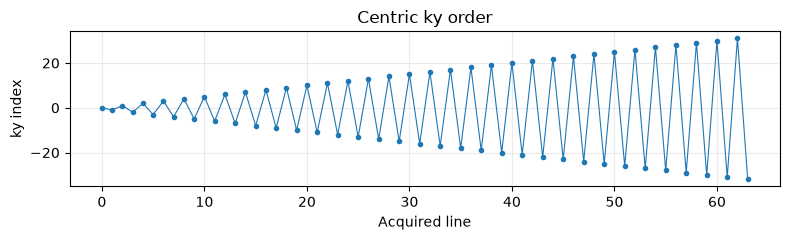

In [40]:
ky_index = np.arange(-n_y // 2, n_y // 2)
ky_order = ky_index[np.lexsort((ky_index, abs(ky_index)))]
assert np.array_equal(ky_order[:10], [0, -1, 1, -2, 2, -3, 3, -4, 4, -5])
print("First 10 ky indices:", ky_order[:10])

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(np.arange(n_y), ky_order, ".-", linewidth=0.8)
ax.set(xlabel="Acquired line", ylabel="ky index", title="Centric ky order")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### TE, inner TR and effective inversion timing

`tr_inner` is measured **between starts of successive low-flip TFL excitation
blocks**. Retain MATLAB's TE/TR formulas and ceiling to the gradient raster.
`first_rf_to_adc_center` retains the source formula's excitation-block-start
convention. `ti_eff` retains its full-preparation-midpoint convention, using
the **played**, serialized pTx duration:

$$TI_{\rm eff}=T_{\rm pTx}/2+T_{\rm crusher}+T_{\rm prepDelay}
+T_{\rm firstRF\to ADCcentre}.$$

In [41]:
raster = system.grad_raster_time
delay_te = np.ceil(
    (te - pp.calc_duration(gx_pre) - gz.fall_time
     - gz.flat_time / 2 - pp.calc_duration(gx) / 2) / raster
) * raster
delay_tr_inner = np.ceil(
    (tr_inner - pp.calc_duration(gz) - pp.calc_duration(gx_pre)
     - pp.calc_duration(gx) - delay_te) / raster
) * raster
assert delay_te >= 0
assert delay_tr_inner >= pp.calc_duration(gx_spoil, gz_spoil)

first_rf_to_adc_center = (
    pp.calc_duration(rf, gz) + pp.calc_duration(gx_pre, gz_reph) + delay_te
    + adc.delay + adc.dwell * adc.num_samples / 2
)
crusher_duration = pp.calc_duration(gz_inv_spoil)
tfl_train_duration = n_rep * n_slices * n_y * tr_inner
print(f"TE delay: {1e6 * delay_te:.0f} us; inner-TR delay: {1e3 * delay_tr_inner:.3f} ms")
print(f"First RF block to ADC centre: {1e3 * first_rf_to_adc_center:.3f} ms")
print(f"Crusher: {1e3 * crusher_duration:.3f} ms; TFL train: {1e3 * tfl_train_duration:.3f} ms")

TE delay: 40 us; inner-TR delay: 1.890 ms
First RF block to ADC centre: 3.280 ms
Crusher: 1.310 ms; TFL train: 384.000 ms


In [42]:
reference_prep_duration = ptx["duration"] + crusher_duration + prep_delay
ti_eff = ptx["duration"] / 2 + crusher_duration + prep_delay + first_rf_to_adc_center
print(f"Matched preparation: {1e3 * reference_prep_duration:.3f} ms; TIeff: {1e3 * ti_eff:.3f} ms")

Matched preparation: 7.830 ms; TIeff: 7.850 ms


### Add the identical TFL train to each arm

MATLAB `addTFLReadout` → Python `add_tfl_readout`.

Assign the current phase to both RF and ADC **before** updating the spoiling
recurrence. Each arm resets phase and increment to zero, so its TFL train is
identical. The post-readout block combines Gx/Gz spoiling with the Gy
phase-encoding rewinder. On the final line, reset LIN to 0 and increment SLC.

In [43]:
def add_tfl_readout(
    seq, system, rf, gz, adc, gx_pre, gz_reph, gx, gx_spoil, gz_spoil,
    ky_order, delta_k, thickness, n_slices, delay_te, delay_tr_inner,
    rf_spoiling_inc, rf_phase, rf_inc,
):
    n_y = len(ky_order)
    for slice_index in range(n_slices):
        rf.freq_offset = gz.amplitude * thickness * (slice_index - (n_slices - 1) / 2)
        for line_index, ky in enumerate(ky_order):
            lin = int(ky + n_y / 2)
            phase_area = -ky * delta_k
            rf.phase_offset = np.deg2rad(rf_phase)
            adc.phase_offset = np.deg2rad(rf_phase)
            rf_inc = (rf_inc + rf_spoiling_inc) % 360
            rf_phase = (rf_phase + rf_inc) % 360

            seq.add_block(rf, gz, pp.make_label("LIN", "SET", lin))
            gy_pre = make_area_trapezoid("y", phase_area, pp.calc_duration(gx_pre), system)
            seq.add_block(gx_pre, gy_pre, gz_reph)
            seq.add_block(pp.make_delay(delay_te))
            seq.add_block(gx, adc)
            gy_reph = pp.scale_grad(gy_pre, -1)
            labels = []
            if line_index == n_y - 1:
                labels = [pp.make_label("LIN", "SET", 0), pp.make_label("SLC", "INC", 1)]
            seq.add_block(pp.make_delay(delay_tr_inner), gx_spoil, gy_reph, gz_spoil, *labels)
    return rf_phase, rf_inc

## Sequence and reference arm — REP 0

Re-run the sequence initialization and both arm cells together after any edit.
The initial REV flag and REP/SLC/LIN labels match MATLAB. Constant gradients
are registered once; RF and ADC remain mutable for spoiling.

The matched reference preparation contains only a delay of `ptx["duration"]`,
the same inversion crusher, and the optional preparation delay. There is
**no pTx RF or RF_SHIMS event in the reference preparation**.

In [44]:
seq = pp.Sequence(system)
for grad in (gz, gx_pre, gz_reph, gx, gx_spoil, gz_spoil):
    grad.id = seq.register_grad_event(grad)
seq.add_block(pp.make_label("REV", "SET", 1))

In [45]:
seq.add_block(
    pp.make_label("REP", "SET", 0),
    pp.make_label("SLC", "SET", 0),
    pp.make_label("LIN", "SET", 0),
)
rf_phase = 0
rf_inc = 0
reference_prep_start = sum(seq.block_durations.values())
seq.add_block(pp.make_delay(ptx["duration"]))
seq.add_block(gz_inv_spoil)
if prep_delay > 0:
    seq.add_block(pp.make_delay(prep_delay))
rf_phase, rf_inc = add_tfl_readout(
    seq, system, rf, gz, adc, gx_pre, gz_reph, gx, gx_spoil, gz_spoil,
    ky_order, delta_k, thickness, n_slices, delay_te, delay_tr_inner,
    rf_spoiling_inc, rf_phase, rf_inc,
)
reference_acq_end = sum(seq.block_durations.values())

## Recovery between arms

Increment REP before the recovery delay, as in MATLAB. The 10 s delay is an
editable, experiment-specific choice intended to allow recovery after the
reference low-flip train. Select it from the longest relevant T1; approximately
5 × T1 leaves <0.7% residual deviation for simple exponential recovery.

In [46]:
seq.add_block(
    pp.make_label("REP", "INC", 1),
    pp.make_label("SLC", "SET", 0),
    pp.make_label("LIN", "SET", 0),
)
seq.add_block(pp.make_delay(recovery_delay))

## Inversion arm — REP 1

Spokes contain RF + Gz + `pp.make_rf_shim(shim)`. Moment blocks contain their
gradients. Only an event-free timing block needs an explicit delay; no extra
delay is added alongside pTx RF/gradient events. The crusher and centric TFL
then match the reference arm.

In [47]:
rf_phase = 0
rf_inc = 0
inversion_prep_start = sum(seq.block_durations.values())
for block in ptx["blocks"]:
    if block["type"] == "spoke":
        seq.add_block(block["rf"], *block["grad"], pp.make_rf_shim(block["shim"]))
    elif block["grad"]:
        seq.add_block(*block["grad"])
    elif block["duration"] > 0:
        seq.add_block(pp.make_delay(block["duration"]))
seq.add_block(gz_inv_spoil)
if prep_delay > 0:
    seq.add_block(pp.make_delay(prep_delay))
rf_phase, rf_inc = add_tfl_readout(
    seq, system, rf, gz, adc, gx_pre, gz_reph, gx, gx_spoil, gz_spoil,
    ky_order, delta_k, thickness, n_slices, delay_te, delay_tr_inner,
    rf_spoiling_inc, rf_phase, rf_inc,
)
total_sequence_duration = sum(seq.block_durations.values())

## Timing check and definitions

Inspect timing errors before exporting. `RequiredExtensions` and `TxChannels`
retain the MATLAB interpreter requirements; the NPZ must describe the matching
eight-channel pulse. TE and TR definitions retain the requested experiment
values and their source conventions.

In [48]:
timing_ok, timing_errors = seq.check_timing(print_errors=True)
if not timing_ok:
    raise RuntimeError("Sequence timing failed; see the report above.")
print(f"Timing check passed. Total duration: {total_sequence_duration:.6f} s")

Timing check passed. Total duration: 10.783660 s


In [49]:
seq.set_definition("FOV", [fov, fov, thickness])
seq.set_definition("Name", "tfl_reference_inversion")
seq.set_definition("TE", te)
seq.set_definition("TR", tr_inner)
seq.set_definition("RequiredExtensions", "RF_SHIMS")
seq.set_definition("TxChannels", 8)

## Export

Write `tfl_reference_inversion_<pulse_stem>.seq` in the notebook's working
directory, without a signature as in MATLAB. An existing file is left in place;
explicitly move or remove it before intentionally regenerating that output.

In [50]:
if not timing_ok:
    raise RuntimeError("Resolve the sequence timing errors before export.")
# if seq_file.exists():
#     raise FileExistsError(seq_file)
seq.write(str(seq_file), create_signature=True)
print(f"Sequence written: {seq_file.resolve()}")

Sequence written: /Users/jchen/Cambridge/Programming/GitLab/pulseq/pypulseq/examples/notebooks/output/writeTFL/tfl_reference_inversion_3spoke_LUT_180_py.seq


## Sequence visualization

Each view contains only its preparation, crusher, optional preparation delay,
and TFL train. The long recovery delay is outside both ranges. REP/LIN/SLC
labels are shown at ADC events. RF is the scalar waveform; RF_SHIMS determines
its per-channel encoding during the inversion preparation.

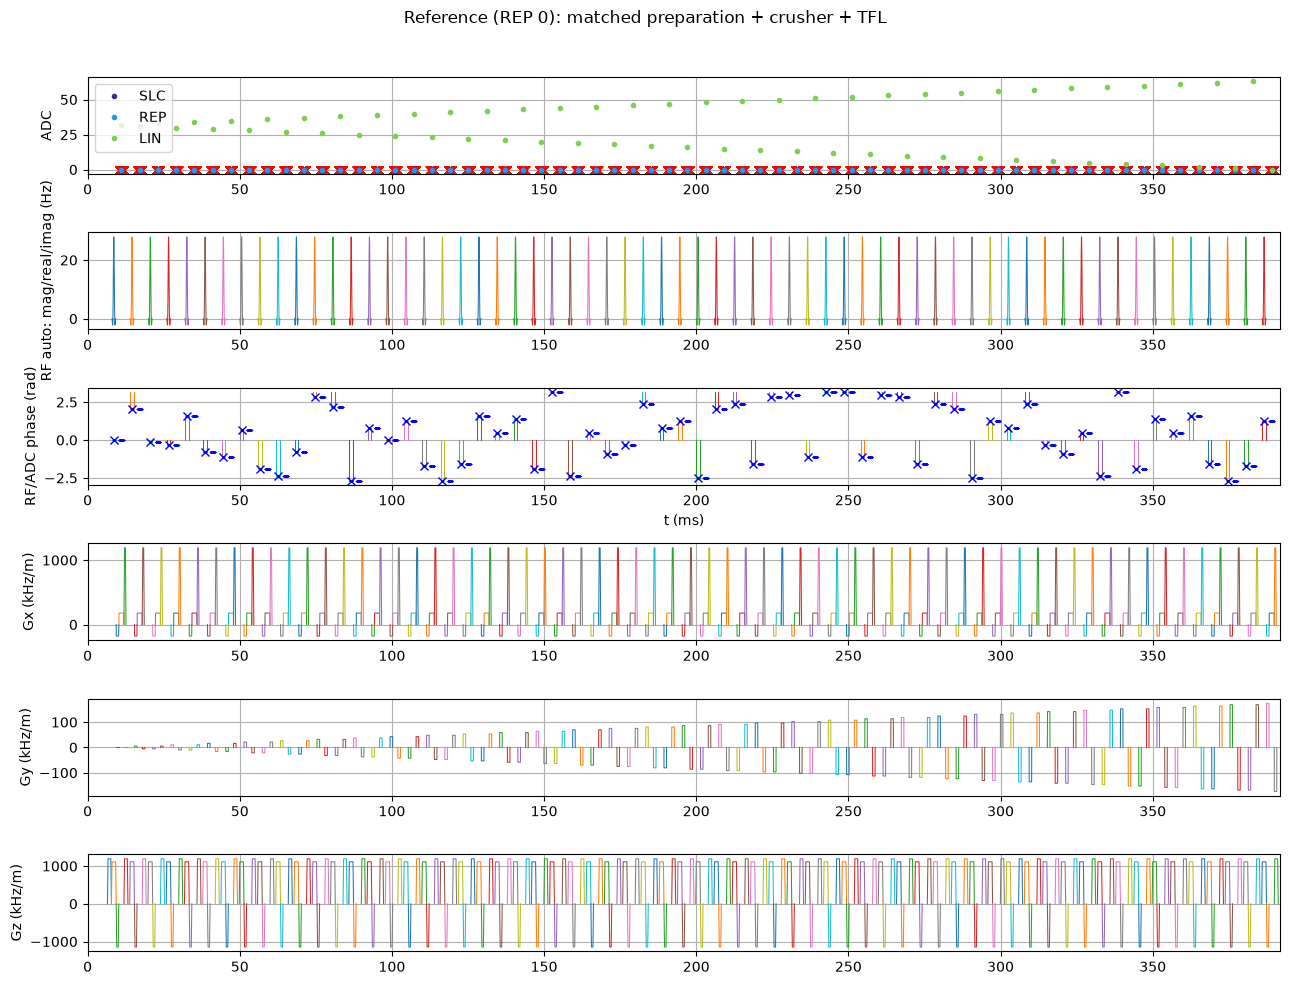

In [51]:
reference_plot = seq.plot(
    time_range=(reference_prep_start, reference_acq_end),
    time_disp="ms", label="REP,LIN,SLC", stacked=True, plot_now=False,
)
reference_plot.fig1.set_size_inches(13, 10)
reference_plot.fig1.suptitle("Reference (REP 0): matched preparation + crusher + TFL")
reference_plot.fig1.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

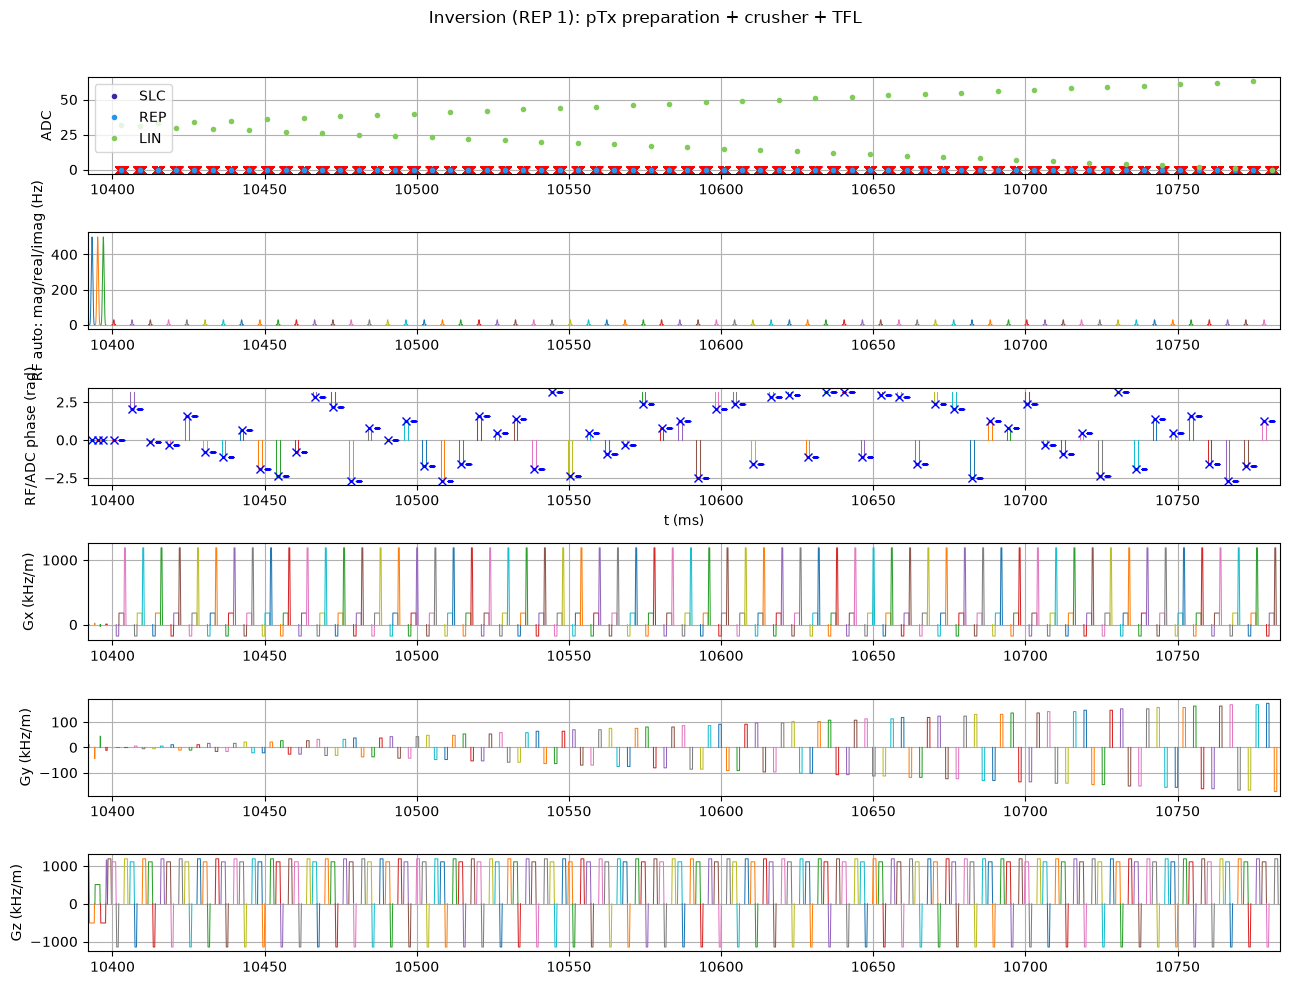

In [52]:
inversion_plot = seq.plot(
    time_range=(inversion_prep_start, total_sequence_duration),
    time_disp="ms", label="REP,LIN,SLC", stacked=True, plot_now=False,
)
inversion_plot.fig1.set_size_inches(13, 10)
inversion_plot.fig1.suptitle("Inversion (REP 1): pTx preparation + crusher + TFL")
inversion_plot.fig1.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## MATLAB → Python parity record

| Component | Correspondence |
| --- | --- |
| Experiment/system | Same FOV, matrix, slice, flip, TE/TR, spoiling, repetitions, delays, limits, dead times and rasters. |
| Spoke detection | Every `rf_detail[:, 1] == 1` row; spacing of three source rows, no fixed spoke count. |
| RF packages/shims | Full three-row packages; direct peak `b_est / rf_form`; unchanged 500 Hz / 223 V encoding. |
| PRE | XY before first active row; Z/duration before first RF/Z package. |
| Spoke Gz | Ordinary trapezoid, package Z area, RF-event duration; exact scalar RF samples. |
| XY blips | Source rows between consecutive active RF rows; XY only. |
| POST | Remaining XY after final active row; Z/duration after final RF/Z package. |
| Scientific invariants | Source/reconstructed RF-centre kxy and total moments, with MATLAB tolerances. |
| TFL/readout | 3° sinc, identical apodization/TBW/slice, 1.6 ms ADC, prephasers and MATLAB ramp calculation. |
| Centric order | Sort by absolute ky, then signed ky. |
| Crusher/spoilers | Same Z inversion crusher, X/Z TFL spoilers and Gy rewind. |
| RF spoiling | Assign RF/ADC phase before updating increment and phase; reset both arms. |
| Labels | Initial REV; REP 0/1; centric LIN; final LIN reset/SLC increment; no ACQ. |
| Arms/recovery | Matched preparation delay vs pTx; identical crusher/TFL; 10 s between arms. |
| Timing/definitions | Same raster-ceiled TE/TR, first RF-to-ADC formula, TIeff convention, FOV/Name/TE/TR/RequiredExtensions/TxChannels. |
| RF_SHIMS | Native local `pp.make_rf_shim`, using the existing MATLAB/interpreter extension format. |

**Intentional input-format difference:** `.mat` input → `.npz` input.
**Other sequence-algorithm differences:** none intended. The local RF_SHIMS
API addition enables this port; the trapezoid helper compensates for the
existing Python/MATLAB API difference without changing the played algorithm.
Export also refuses to overwrite an existing file, as requested.

Full pulse-dependent parity and final sequence timing remain to be checked
with the real NPZ. The assertions above perform those scientific checks when
it is supplied; no substitute pulse has been used to claim end-to-end validity.

## Future simulation

The generated `.seq` can later be passed to MRzero or a conventional Bloch
simulator. Simulation is intentionally outside the scope of this initial port.